In [1]:
import os
print(os.listdir())

['AMF_US-ARM_BASE_HH_15-5.csv', 'AMF_US-ARM_BIF_20240229.xlsx', 'Prediction_USing_ML_Model.ipynb', 'reanalysis-era5-land-timeseries-sfc-2m-temperaturectwi9b5c.csv', 'reanalysis-era5-land-timeseries-sfc-2m-temperaturenvjcpbxi.csv', 'reanalysis-era5-land-timeseries-sfc-pressure-precipitationp58iih4w.csv', 'reanalysis-era5-land-timeseries-sfc-radiation-heatyz_opg_o.csv', 'reanalysis-era5-land-timeseries-sfc-soil-temperature_szthbx0.csv', 'reanalysis-era5-land-timeseries-sfc-soil-watery5wmeq3m.csv']


In [2]:
import pandas as pd

df_era = pd.read_csv("reanalysis-era5-land-timeseries-sfc-soil-watery5wmeq3m.csv")

# convert time
df_era["valid_time"] = pd.to_datetime(df_era["valid_time"])
df_era.set_index("valid_time", inplace=True)

# keep only soil moisture
df_era = df_era[['swvl1']]

print(df_era.head())

                        swvl1
valid_time                   
2003-01-01 00:00:00  0.328949
2003-01-01 01:00:00  0.328629
2003-01-01 02:00:00  0.328323
2003-01-01 03:00:00  0.328064
2003-01-01 04:00:00  0.327805


In [3]:
df_flux = pd.read_csv("AMF_US-ARM_BASE_HH_15-5.csv", skiprows=2, na_values=-9999)

# convert time
df_flux["TIMESTAMP_START"] = pd.to_datetime(
    df_flux["TIMESTAMP_START"], format='%Y%m%d%H%M'
)

# keep only soil moisture
df_flux = df_flux[['TIMESTAMP_START', 'SWC_1_1_1']].dropna()

# set index
df_flux.set_index("TIMESTAMP_START", inplace=True)

# convert half-hourly → hourly
df_flux = df_flux.resample('h').mean()

# convert % → m³/m³
df_flux["SWC_1_1_1"] = df_flux["SWC_1_1_1"] / 100

print(df_flux.head())

                     SWC_1_1_1
TIMESTAMP_START               
2003-01-01 18:00:00    0.27205
2003-01-01 19:00:00    0.27175
2003-01-01 20:00:00    0.27165
2003-01-01 21:00:00    0.27165
2003-01-01 22:00:00    0.27165


In [4]:
start = max(df_era.index.min(), df_flux.index.min())
end   = min(df_era.index.max(), df_flux.index.max())

df_era = df_era.loc[start:end]
df_flux = df_flux.loc[start:end]

print(df_era.shape, df_flux.shape)

(70080, 1) (70080, 1)


In [5]:
df = df_era.merge(df_flux, left_index=True, right_index=True)

print("Final dataset:", df.shape)
print(df.head())

Final dataset: (70080, 2)
                        swvl1  SWC_1_1_1
valid_time                              
2003-01-01 18:00:00  0.323135    0.27205
2003-01-01 19:00:00  0.322495    0.27175
2003-01-01 20:00:00  0.321869    0.27165
2003-01-01 21:00:00  0.321381    0.27165
2003-01-01 22:00:00  0.321121    0.27165


In [6]:
df = df.dropna()

In [7]:
corr = df['swvl1'].corr(df['SWC_1_1_1'])
print("Correlation:", corr)

Correlation: 0.6080544740100793


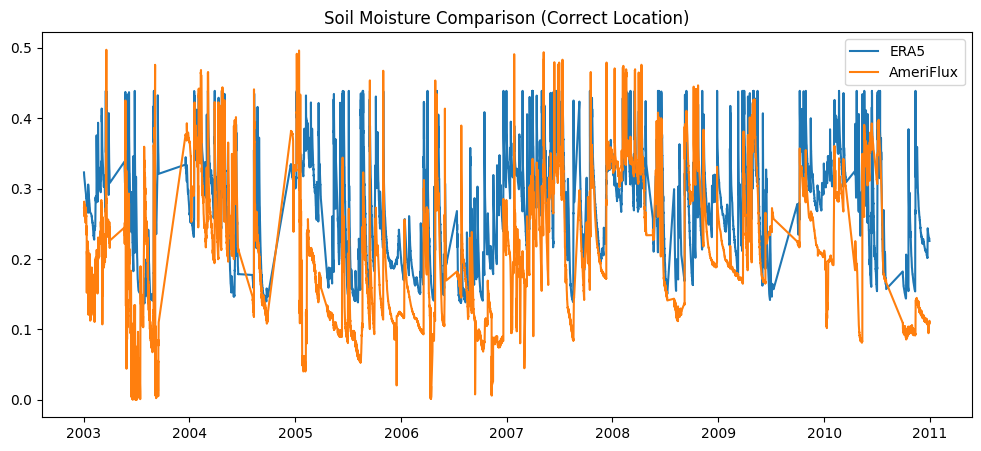

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))

plt.plot(df.index, df['swvl1'], label='ERA5')
plt.plot(df.index, df['SWC_1_1_1'], label='AmeriFlux')

plt.legend()
plt.title("Soil Moisture Comparison (Correct Location)")
plt.show()

In [9]:
features = ['swvl1']
target = 'SWC_1_1_1'

In [10]:
from sklearn.linear_model import LinearRegression

X = df[['swvl1']]
y = df['SWC_1_1_1']

split = int(len(df)*0.7)

X_train = X.iloc[:split]
X_test  = X.iloc[split:]

y_train = y.iloc[:split]
y_test  = y.iloc[split:]

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [11]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

RMSE: 0.07488283669873491
R2: 0.23256699076883103


In [12]:
df_temp = pd.read_csv("reanalysis-era5-land-timeseries-sfc-2m-temperaturenvjcpbxi.csv")
df_precip = pd.read_csv("reanalysis-era5-land-timeseries-sfc-pressure-precipitationp58iih4w.csv")

In [13]:
# Temperature
df_temp["valid_time"] = pd.to_datetime(df_temp["valid_time"])
df_temp.set_index("valid_time", inplace=True)
df_temp = df_temp[['t2m']]

# Precipitation
df_precip["valid_time"] = pd.to_datetime(df_precip["valid_time"])
df_precip.set_index("valid_time", inplace=True)
df_precip = df_precip[['tp']]

In [14]:
df = df.merge(df_temp, left_index=True, right_index=True)
df = df.merge(df_precip, left_index=True, right_index=True)

df = df.dropna()

In [15]:
features = ['swvl1', 'tp', 't2m']
target = 'SWC_1_1_1'

X = df[features]
y = df[target]

In [16]:
from sklearn.ensemble import RandomForestRegressor

split = int(len(df)*0.7)

X_train = X.iloc[:split]
X_test  = X.iloc[split:]
y_train = y.iloc[:split]
y_test  = y.iloc[split:]

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [17]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

RMSE: 0.08425093128133984
R2: 0.028539112845007986


In [18]:
df['tp_3day'] = df['tp'].rolling(24*3).sum()
df['tp_7day'] = df['tp'].rolling(24*7).sum()

df = df.dropna()

In [19]:
features = ['swvl1', 'tp_3day', 'tp_7day']

In [20]:
X = df[['swvl1', 'tp_3day', 'tp_7day']]
y = df['SWC_1_1_1']

In [21]:
split = int(len(df)*0.7)

X_train = X.iloc[:split]
X_test  = X.iloc[split:]

y_train = y.iloc[:split]
y_test  = y.iloc[split:]

In [22]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [23]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

RMSE: 0.08599293486347635
R2: -0.012954067982506645


In [24]:
# remove VPD part completely

# continue with lag features
df['swvl1_lag24'] = df['swvl1'].shift(24)

df['tp_lag24'] = df['tp'].shift(24)
df['tp_lag72'] = df['tp'].shift(72)

df['tp_3day'] = df['tp'].rolling(24*3).sum().shift(1)
df['tp_7day'] = df['tp'].rolling(24*7).sum().shift(1)

df_corr = df.dropna().copy()

In [25]:
features = [
    'swvl1',
    'swvl1_lag24',
    'tp', 'tp_lag24', 'tp_lag72',
    'tp_3day', 'tp_7day',
    't2m',
    'ssrd'
]

In [26]:
features = [
    'swvl1',
    'swvl1_lag24',
    'tp', 'tp_lag24', 'tp_lag72',
    'tp_3day', 'tp_7day',
    't2m'
]

In [27]:
corr = df_corr[features + ['SWC_1_1_1']].corr()
corr_target = corr['SWC_1_1_1'].drop('SWC_1_1_1').sort_values(ascending=False)

print(corr_target)

swvl1          0.607778
swvl1_lag24    0.568066
tp_7day        0.400163
tp_3day        0.343326
tp             0.141982
tp_lag24       0.128937
tp_lag72       0.104680
t2m           -0.114449
Name: SWC_1_1_1, dtype: float64


In [28]:
from sklearn.ensemble import RandomForestRegressor

X = df_corr[features]
y = df_corr[target]

split = int(len(df_corr)*0.7)

X_train = X.iloc[:split]
X_test  = X.iloc[split:]
y_train = y.iloc[:split]
y_test  = y.iloc[split:]

model = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [29]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

RMSE: 0.08169082656330262
R2: 0.08480798268375711


In [30]:
X = df[['swvl1']]
y = df['SWC_1_1_1']

In [31]:
split = int(len(df)*0.7)

X_train = X.iloc[:split]
X_test  = X.iloc[split:]

y_train = y.iloc[:split]
y_test  = y.iloc[split:]

In [32]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [33]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

RMSE: 0.07711532722117244
R2: 0.18539771903957392


In [34]:
X = df[['swvl1']]
y = df['SWC_1_1_1']

In [35]:
from sklearn.model_selection import train_test_split

# random split (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

In [36]:
from sklearn.linear_model import LinearRegression

lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [37]:
# calibration (train)
y_train_pred_lin = lin_model.predict(X_train)

# validation (test)
y_test_pred_lin = lin_model.predict(X_test)

In [38]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("---- Linear Regression ----")

print("Calibration (Train):")
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred_lin)))
print("R2:", r2_score(y_train, y_train_pred_lin))

print("\nValidation (Test):")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred_lin)))
print("R2:", r2_score(y_test, y_test_pred_lin))

---- Linear Regression ----
Calibration (Train):
RMSE: 0.07434322245388347
R2: 0.3703274531579771

Validation (Test):
RMSE: 0.07461768687338795
R2: 0.3671615811119361


In [39]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [40]:
# calibration
y_train_pred_rf = rf_model.predict(X_train)

# validation
y_test_pred_rf = rf_model.predict(X_test)

In [41]:
print("\n---- Random Forest ----")

print("Calibration (Train):")
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_train_pred_rf)))
print("R2:", r2_score(y_train, y_train_pred_rf))

print("\nValidation (Test):")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred_rf)))
print("R2:", r2_score(y_test, y_test_pred_rf))


---- Random Forest ----
Calibration (Train):
RMSE: 0.07010638981521203
R2: 0.44005263964301766

Validation (Test):
RMSE: 0.07331809732304168
R2: 0.3890134568318898


In [43]:
!pip install h5py

   ---------------------------------------- 0.0/3.2 MB ? eta -:--:--
   - -------------------------------------- 0.1/3.2 MB 2.6 MB/s eta 0:00:02
   -- ------------------------------------- 0.2/3.2 MB 2.4 MB/s eta 0:00:02
   ---- ----------------------------------- 0.3/3.2 MB 2.3 MB/s eta 0:00:02
   -------- ------------------------------- 0.7/3.2 MB 3.2 MB/s eta 0:00:01
   --------- ------------------------------ 0.8/3.2 MB 3.3 MB/s eta 0:00:01
   ------------ --------------------------- 1.0/3.2 MB 3.2 MB/s eta 0:00:01
   ------------- -------------------------- 1.0/3.2 MB 3.0 MB/s eta 0:00:01
   ----------------- ---------------------- 1.4/3.2 MB 3.6 MB/s eta 0:00:01
   ------------------- -------------------- 1.5/3.2 MB 3.6 MB/s eta 0:00:01
   ---------------------- ----------------- 1.8/3.2 MB 3.7 MB/s eta 0:00:01
   ----------------------- ---------------- 1.9/3.2 MB 3.8 MB/s eta 0:00:01
   ------------------------- -------------- 2.0/3.2 MB 3.7 MB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: C:\Users\prath\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [45]:
import h5py

file = h5py.File("SMAP_data/SMAP_L3_SM_P_E_20150401_R19240_001.h5", "r")
print(list(file.keys()))

['Metadata', 'Soil_Moisture_Retrieval_Data_AM', 'Soil_Moisture_Retrieval_Data_PM', 'Soil_Moisture_Retrieval_Data_Polar_AM', 'Soil_Moisture_Retrieval_Data_Polar_PM']


In [46]:
grp = file['Soil_Moisture_Retrieval_Data_AM']

print(list(grp.keys()))

['EASE_column_index', 'EASE_row_index', 'albedo', 'albedo_dca', 'albedo_scah', 'albedo_scav', 'boresight_incidence', 'bulk_density', 'clay_fraction', 'freeze_thaw_fraction', 'grid_surface_status', 'latitude', 'latitude_centroid', 'longitude', 'longitude_centroid', 'radar_water_body_fraction', 'retrieval_qual_flag', 'retrieval_qual_flag_dca', 'retrieval_qual_flag_scah', 'retrieval_qual_flag_scav', 'roughness_coefficient', 'roughness_coefficient_dca', 'roughness_coefficient_scah', 'roughness_coefficient_scav', 'soil_moisture', 'soil_moisture_dca', 'soil_moisture_error', 'soil_moisture_scah', 'soil_moisture_scav', 'static_water_body_fraction', 'surface_flag', 'surface_temperature', 'surface_water_fraction_mb_h', 'surface_water_fraction_mb_v', 'tb_3_corrected', 'tb_4_corrected', 'tb_h_corrected', 'tb_h_uncorrected', 'tb_qual_flag_3', 'tb_qual_flag_4', 'tb_qual_flag_h', 'tb_qual_flag_v', 'tb_time_seconds', 'tb_time_utc', 'tb_v_corrected', 'tb_v_uncorrected', 'vegetation_opacity', 'vegetatio

In [47]:
import numpy as np

grp = file['Soil_Moisture_Retrieval_Data_AM']

sm = grp['soil_moisture'][:]
lat = grp['latitude'][:]
lon = grp['longitude'][:]

print(sm.shape)

(1624, 3856)


In [48]:
import numpy as np

# Your AmeriFlux site coordinates (US-ARM)
target_lat = 36.6058
target_lon = -97.4888

# lat, lon, sm are already extracted from SMAP file
# lat = latitude grid (2D)
# lon = longitude grid (2D)
# sm  = soil moisture grid (2D)

# Step 1: Calculate distance of each pixel from your site
# Using squared distance (no need for square root)
dist = (lat - target_lat)**2 + (lon - target_lon)**2

# Step 2: Find index of nearest pixel
# argmin gives position of minimum distance
# unravel_index converts it to 2D index
idx = np.unravel_index(np.argmin(dist), dist.shape)

# Step 3: Extract soil moisture at that pixel
smap_value = sm[idx]

# Step 4: Print result
print("Nearest pixel index:", idx)
print("SMAP Soil Moisture at your location:", smap_value)

Nearest pixel index: (np.int64(327), np.int64(883))
SMAP Soil Moisture at your location: 0.116766594


In [51]:
import os
import h5py
import numpy as np
import pandas as pd

# Folder where all SMAP .h5 files are stored
folder = "SMAP_data"

# AmeriFlux site coordinates (US-ARM)
target_lat = 36.6058
target_lon = -97.4888

# Lists to store results
values = []
dates = []

# Loop through all SMAP files in the folder
for file_name in os.listdir(folder):
    
    # Process only .h5 files
    if file_name.endswith(".h5"):
        
        # Create full file path
        file_path = os.path.join(folder, file_name)
        
        # Open SMAP file
        f = h5py.File(file_path, "r")
        
        # Access AM soil moisture data group
        grp = f['Soil_Moisture_Retrieval_Data_AM']
        
        # Extract required variables
        sm = grp['soil_moisture'][:]   # soil moisture grid
        lat = grp['latitude'][:]       # latitude grid
        lon = grp['longitude'][:]      # longitude grid
        
        # Compute distance of each pixel from target location
        dist = (lat - target_lat)**2 + (lon - target_lon)**2
        
        # Find nearest pixel index
        idx = np.unravel_index(np.argmin(dist), dist.shape)
        
        # Extract soil moisture value at that pixel
        sm_value = sm[idx]
        
        # Store value
        values.append(sm_value)
        
        # Extract date from file name (YYYYMMDD format)
        date_str = file_name.split('_')[5]
        dates.append(date_str)
        
        # Close file
        f.close()

# Convert results into DataFrame
smap_df = pd.DataFrame({
   'time': pd.to_datetime(dates, format='%Y%m%d'),
    'smap_sm': values
})

# Sort by time
smap_df = smap_df.sort_values('time')

# Display result
print(smap_df)

        time   smap_sm
0 2015-04-01  0.116767
1 2015-04-02  0.383791
2 2015-04-03  0.116937
3 2015-04-04  0.097353
4 2015-04-05  0.249756


In [65]:
df_reset = df.reset_index()

In [66]:
df_reset['valid_time'] = pd.to_datetime(df_reset['valid_time'])

In [67]:
df_reset['date'] = df_reset['valid_time'].dt.date
smap_df['date'] = smap_df['time'].dt.date

In [68]:
df_daily = df_reset.groupby('date').agg({
    'SWC_1_1_1': 'mean',
    'swvl1': 'mean'
}).reset_index()

In [69]:
df_compare = df_daily.merge(smap_df, on='date', how='inner')

In [70]:
df_compare['ML_Model'] = rf_model.predict(df_compare[['swvl1']])

ValueError: Found array with 0 sample(s) (shape=(0, 1)) while a minimum of 1 is required by RandomForestRegressor.